# SNOWPACK soil sensitivity: PPSA, TRAM, and HEEN

Compare **four lapse-rate simulations per site**: HRRR-AK base / soil and met + HRRR-AK base / soil. No non-lapse-rate model files are loaded. Observations and the three-site layout follow `3_read_snowpack_output_compare_all_sites_lapserate_figure.ipynb`; that notebook is unchanged.

The soil experiments add the PPSA-style 28-layer, 5 m idealized mineral-loam column with Richards water transport, Cosenza conductivity, and an assumed upward 0.06 W/m² basal flux. Snow physics and forcing remain those of each corresponding base run. These are sensitivity experiments, not calibrated site soil profiles. First seasons are initialization-sensitive; shorter mixed-forcing runs have less soil spin-up than six-year HRRR runs. Compare **within a forcing pair** to isolate the soil-setup effect.

Run all cells to display figures inline and regenerate diagnostic CSV tables in `temporary/soil_comparison/`. Model/observation timestamps follow the project's UTC convention. All plotted snow depths are **cm**, explicitly converted from each SMET's unit metadata. Model filenames retain the project's period names; actual endpoints are checked below.

Run verification: all four TRAM/HEEN soil runs completed without solver failures or missing required modeled variables; profiles/restarts contain 28 soil elements totaling 5 m. Original forcing, zero-layer profiles, base configurations and selected base SMET outputs match pre-run checksums. Per-site `README_soil.md`, `run_soil.sh`, `verify_soil_runs.py`, and `soil_run_verification.json` live in `/home/cassie/python/models/run_snowpack/sites/{tram,heen}/`. HEEN's mixed-forcing run retains large-snowfall warnings on 2021-02-09 and 2022-02-01 with the original forcing unchanged; the corresponding snow-depth spikes are visible in the comparison and were not corrected or tuned here.

Analysis figures display inline and are not saved automatically. Diagnostic tables, caches, and copied inputs go to the ignored `temporary/` folder. Export only explicitly selected final figures to `figures/`.


In [1]:
from pathlib import Path
from io import StringIO
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
MODEL_ROOT = Path(os.environ.get('SNOWPACK_SITES', '/home/cassie/python/models/run_snowpack/sites'))
REPO_ROOT = Path('/home/cassie/python/repos/snow_modeling_point')
FIGURE_DIR = REPO_ROOT / 'temporary' / 'soil_comparison'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SITE_CONFIG = {
    'ppsa': dict(title='Powder Patch (PPSA)', hrrr='WY2020-WY2025', mixed='WY2020-WY2025',
                 plot_start='2022-10-01', plot_end='2025-09-01',
                 obs='/hdd/snow_hydrology/met_station/ppsa2/pppsa_met_station_data_synoptic_2026-03-20'),
    'tram': dict(title='Mount Roberts Tramway (TRAM)', hrrr='WY2020-WY2025', mixed='WY2023-WY2025',
                 plot_start='2022-10-01', plot_end='2025-09-01',
                 obs='/hdd/snow_hydrology/met_station/tram/tram_met_station_data_synoptic_2026-03-20'),
    'heen': dict(title='Heen Latinee (HEEN)', hrrr='WY2020-WY2025', mixed='WY2020-WY2022',
                 plot_start='2019-10-01', plot_end='2022-09-30',
                 obs='/hdd/snow_hydrology/met_station/snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc'),
}
FORCINGS = {'hrrr': 'hrrrak_lapserate', 'mixed': 'met_hrrrak_lapserate'}
COLORS = {'hrrr': '#0072B2', 'mixed': '#D55E00'}
LABELS = {'hrrr': 'HRRR-AK lapse-rate', 'mixed': 'Met + HRRR-AK lapse-rate'}
STYLES = {'base': '-', 'soil': '--'}
# Melt-out definitions are adjustable and are included in the exported tables.
SNOW_FREE_CM = 1.0
SWE_FREE_KG_M2 = 1.0
SNOW_FREE_DAYS = 7
MIN_VALID_HOURS_PER_DAY = 18
MIN_SEASON_PEAK_CM = 10.0


## Load only the 12 requested model files

The reader replaces the file's nodata value before applying `units_multiplier` and `units_offset`. It returns snow height in cm and SWE in kg/m². It rejects duplicate or missing hourly model timestamps. Soil and base are joined by actual timestamps; no initial hour is fabricated or shifted.

In [2]:
def read_smet_snow(path):
    header = {}
    with Path(path).open() as stream:
        for line in stream:
            line = line.strip()
            if line == '[DATA]':
                break
            if '=' in line and not line.startswith('#'):
                key, value = line.split('=', 1)
                header[key.strip()] = value.strip()
        else:
            raise ValueError(f'No [DATA] section: {path}')
        fields = header['fields'].split()
        raw = pd.read_csv(stream, sep=r'\s+', names=fields)
    if float(header.get('tz', 0)) != 0:
        raise ValueError(f'Expected UTC model output: {path}')
    time = pd.to_datetime(raw.pop('timestamp'), utc=True).dt.tz_convert(None)
    raw.index = pd.DatetimeIndex(time, name='time')
    raw = raw.replace(float(header.get('nodata', -999)), np.nan)
    multipliers = np.array(header['units_multiplier'].split(), dtype=float)
    offsets = np.array(header['units_offset'].split(), dtype=float)
    if len(multipliers) != len(fields) or len(offsets) != len(fields):
        raise ValueError(f'Unit metadata does not match fields: {path}')
    result = pd.DataFrame(index=raw.index)
    for source, target, factor in [('HS_mod', 'HS_cm', 100.0), ('SWE', 'SWE_kg_m2', 1.0)]:
        i = fields.index(source)
        result[target] = (pd.to_numeric(raw[source]) * multipliers[i] + offsets[i]) * factor
    if not result.index.is_unique or not result.index.is_monotonic_increasing:
        raise ValueError(f'Duplicate or unsorted timestamps: {path}')
    if not result.index.to_series().diff().iloc[1:].eq(pd.Timedelta(hours=1)).all():
        raise ValueError(f'Non-hourly or missing timestamps: {path}')
    if not np.isfinite(result.to_numpy()).all():
        raise ValueError(f'Missing modeled snow depth/SWE: {path}')
    return result, header

models, headers, file_rows = {}, {}, []
for site, config in SITE_CONFIG.items():
    for forcing, prefix in FORCINGS.items():
        period = config[forcing]
        stem = f'{prefix}_{site}_{period}'
        for experiment in ('base', 'soil'):
            path = MODEL_ROOT / site / 'output' / f'{stem}_{experiment}.smet'
            key = (site, forcing, experiment)
            models[key], headers[key] = read_smet_snow(path)
            df = models[key]
            file_rows.append(dict(site=site, forcing=forcing, experiment=experiment,
                                  file=path.name, start_UTC=df.index.min(), end_UTC=df.index.max(),
                                  hourly_records=len(df), HS_raw_to_cm=float(headers[key]['units_multiplier'].split()[headers[key]['fields'].split().index('HS_mod')]) * 100))
assert len(models) == 12
coverage = pd.DataFrame(file_rows)
coverage.to_csv(FIGURE_DIR / 'model_file_coverage.csv', index=False)
display(coverage)


,site,forcing,experiment,file,start_UTC,end_UTC,hourly_records,HS_raw_to_cm
0,ppsa,hrrr,base,hrrrak_lapserate_ppsa_WY2020-WY2025_base.smet,2019-10-01 05:00:00,2025-09-01 00:00:00,51884,1.0
1,ppsa,hrrr,soil,hrrrak_lapserate_ppsa_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,1.0
2,ppsa,mixed,base,met_hrrrak_lapserate_ppsa_WY2020-WY2025_base.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,1.0
3,ppsa,mixed,soil,met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,1.0
4,tram,hrrr,base,hrrrak_lapserate_tram_WY2020-WY2025_base.smet,2019-10-01 05:00:00,2025-09-01 00:00:00,51884,1.0
5,tram,hrrr,soil,hrrrak_lapserate_tram_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,1.0
6,tram,mixed,base,met_hrrrak_lapserate_tram_WY2023-WY2025_base.smet,2022-10-01 06:00:00,2025-09-01 00:00:00,25579,1.0
7,tram,mixed,soil,met_hrrrak_lapserate_tram_WY2023-WY2025_soil.smet,2022-10-01 06:00:00,2025-09-01 00:00:00,25579,1.0
8,heen,hrrr,base,hrrrak_lapserate_heen_WY2020-WY2025_base.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,1.0
9,heen,hrrr,soil,hrrrak_lapserate_heen_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,1.0


In [3]:
observations, observation_rows = {}, []
for site, config in SITE_CONFIG.items():
    with xr.open_dataset(config['obs']) as ds:
        series = ds['hs'].to_series().copy()
        units = str(ds['hs'].attrs.get('units', '')).strip().lower()
    if units in ('m', 'meter', 'meters', 'metre', 'metres'):
        series *= 100
    elif units not in ('cm', 'centimeter', 'centimeters', 'centimetre', 'centimetres'):
        raise ValueError(f'Unsupported observation snow-height units for {site}: {units!r}')
    series.index = pd.DatetimeIndex(pd.to_datetime(series.index, utc=True)).tz_convert(None)
    duplicates = int(series.index.duplicated().sum())
    if duplicates:
        series = series.groupby(level=0).mean()
    series = pd.to_numeric(series).sort_index()
    # Negative snow depth is not physical; leave it missing rather than clipping or filling it.
    negative = int((series < 0).sum())
    series = series.where((series >= 0) & np.isfinite(series))
    observations[site] = series.rename('observed_HS_cm')
    observation_rows.append(dict(site=site, source_units=units, negative_values_masked=negative,
                                 duplicate_timestamps_averaged=duplicates, valid_values=series.notna().sum()))
display(pd.DataFrame(observation_rows))

# Join model pairs before calculating changes or observation errors.
paired = {}
for site in SITE_CONFIG:
    for forcing in FORCINGS:
        base = models[(site, forcing, 'base')]
        soil = models[(site, forcing, 'soil')]
        index = base.index.intersection(soil.index)
        if len(index) < min(len(base), len(soil)) - 1:
            raise ValueError(f'Unexpected model coverage mismatch: {site}, {forcing}')
        frame = base.loc[index].add_suffix('_base').join(soil.loc[index].add_suffix('_soil'))
        frame['delta_HS_cm'] = frame.HS_cm_soil - frame.HS_cm_base
        frame['observed_HS_cm'] = observations[site].reindex(index)
        paired[(site, forcing)] = frame


,site,source_units,negative_values_masked,duplicate_timestamps_averaged,valid_values
0,ppsa,cm,0,0,34622
1,tram,cm,0,0,68589
2,heen,cm,0,0,83296


## Main snow-depth comparison

Color identifies forcing; solid is base and dashed is soil. Black is observed depth. PPSA/TRAM show WY2023–WY2025, HEEN WY2020–WY2022, matching the main comparison's three-season layout. The axes retain actual dates; these sites are not being compared over identical climate years. The displayed windows use only dates shared by all four site simulations. All historical records remain available for the seasonal metrics below.

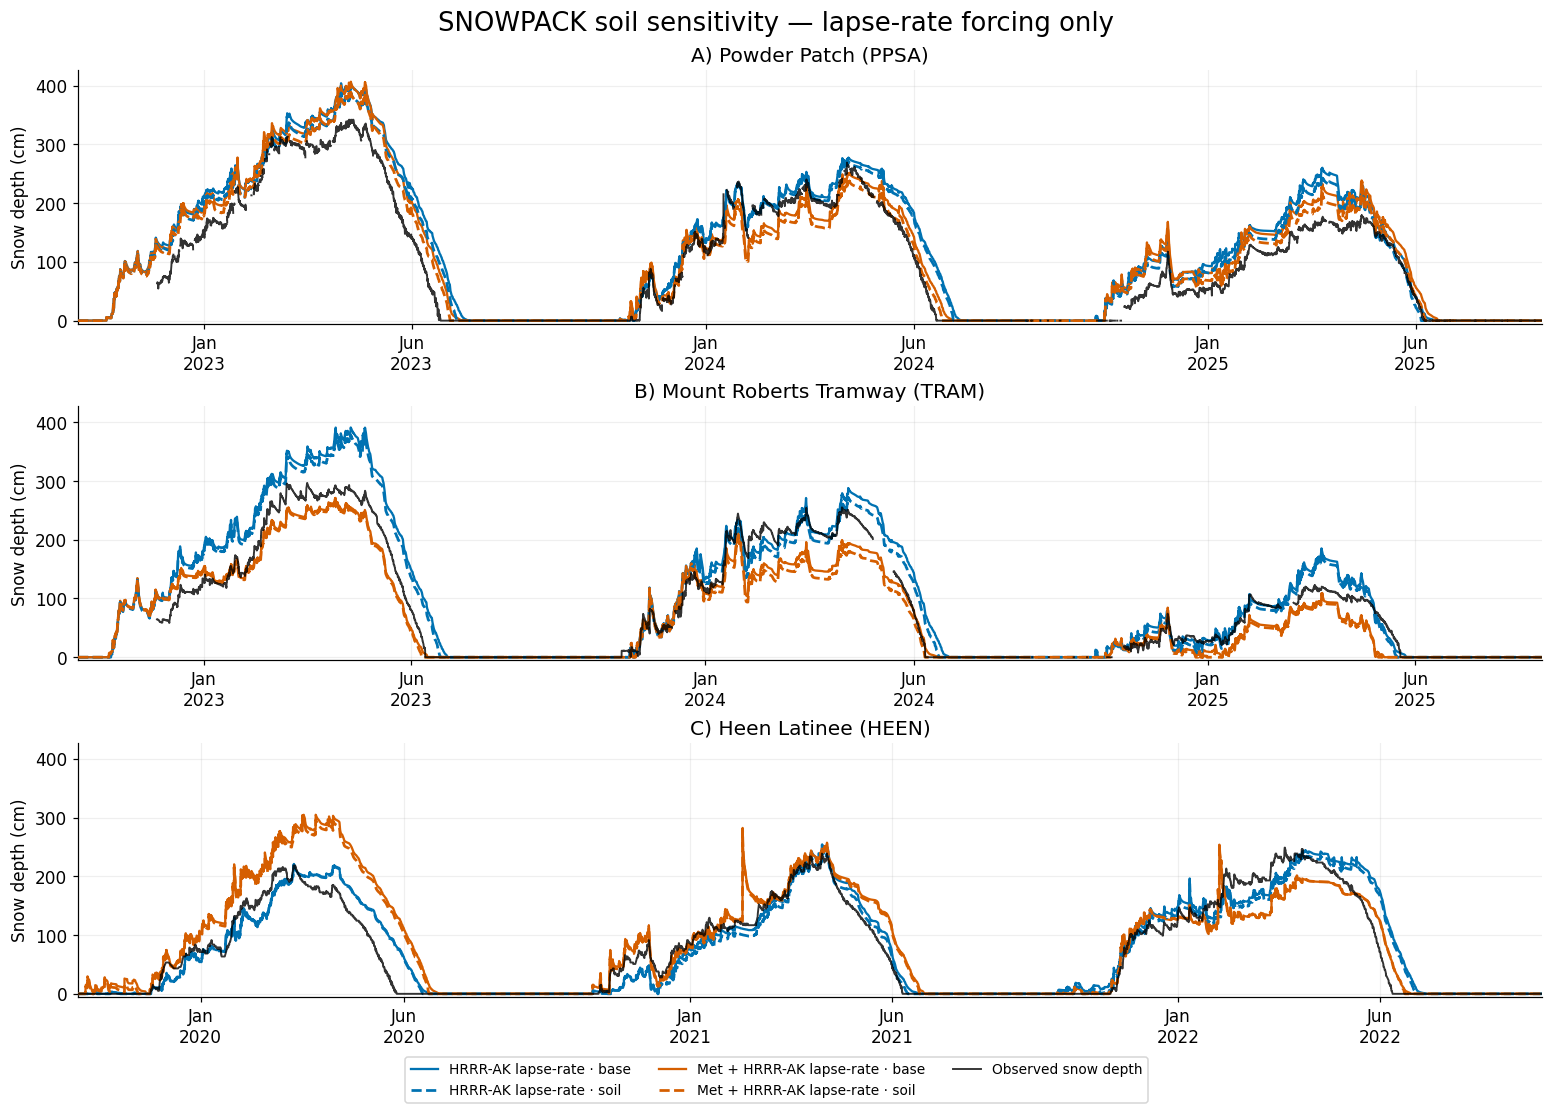

In [4]:

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharey=True, layout='constrained')
plot_windows = {}
for letter, (site, config), ax in zip('ABC', SITE_CONFIG.items(), axes):
    frames = [models[(site, forcing, experiment)] for forcing in FORCINGS for experiment in ('base', 'soil')]
    start = max(pd.Timestamp(config['plot_start']), max(d.index.min() for d in frames))
    end = min(pd.Timestamp(config['plot_end']) + pd.Timedelta(hours=23), min(d.index.max() for d in frames))
    plot_windows[site] = (start, end)
    for forcing in FORCINGS:
        for experiment in ('base', 'soil'):
            curve = models[(site, forcing, experiment)].loc[start:end, 'HS_cm']
            ax.plot(curve.index, curve, color=COLORS[forcing], ls=STYLES[experiment],
                    lw=1.5 if experiment == 'base' else 1.8,
                    label=f'{LABELS[forcing]} · {experiment}', zorder=3 if experiment == 'soil' else 2)
    obs = observations[site].loc[start:end]
    ax.plot(obs.index, obs, color='black', lw=1.25, alpha=.8, label='Observed snow depth', zorder=4)
    ax.set(title=f'{letter}) {config["title"]}', ylabel='Snow depth (cm)', xlim=(start, end))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 6]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.grid(alpha=.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=9)
axes[0].set_ylim(bottom=-5)
fig.suptitle('SNOWPACK soil sensitivity — lapse-rate forcing only', fontsize=17)

plt.show()


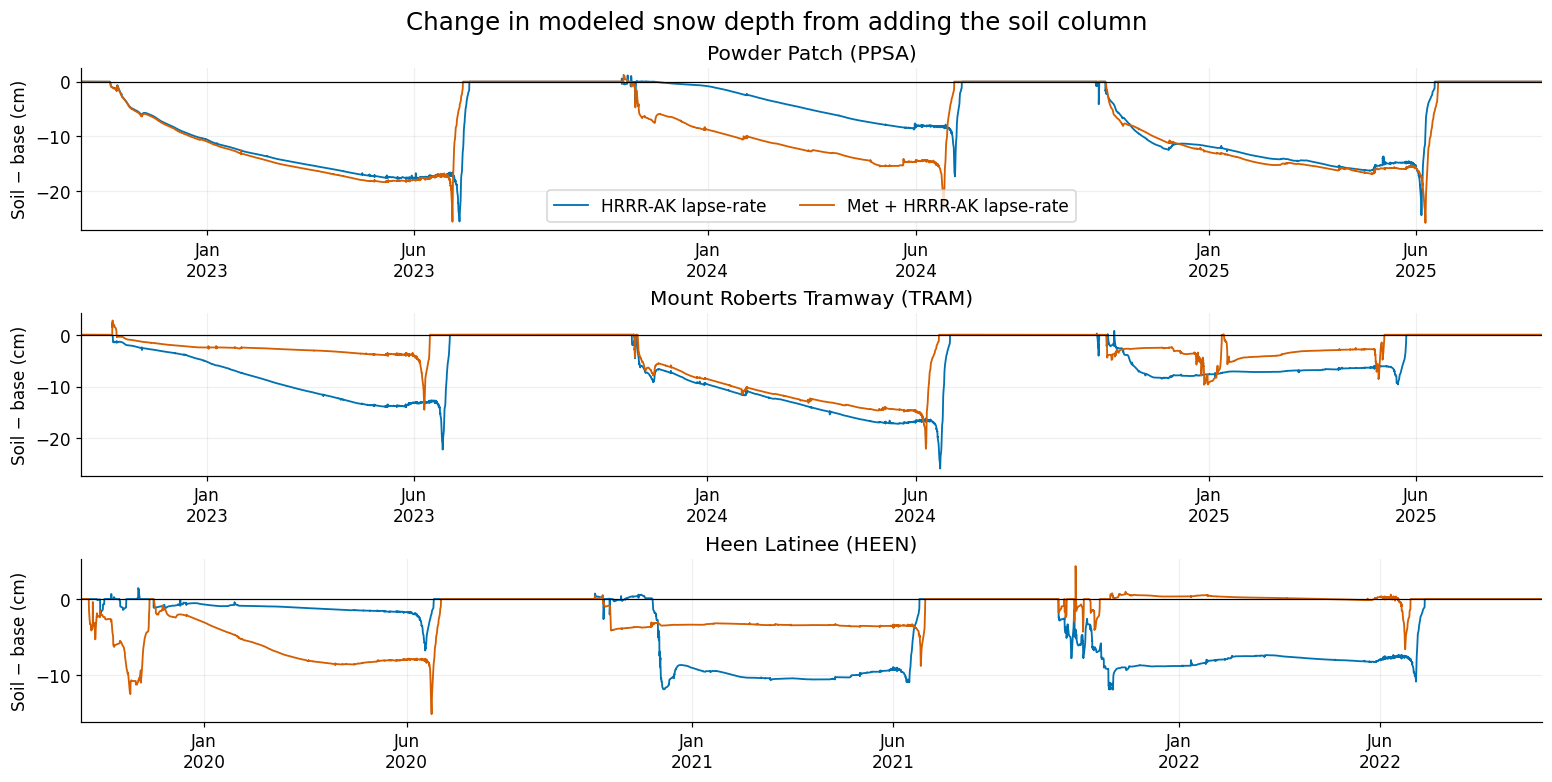

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 7), layout='constrained')
for (site, config), ax in zip(SITE_CONFIG.items(), axes):
    start, end = plot_windows[site]
    for forcing in FORCINGS:
        delta = paired[(site, forcing)].loc[start:end, 'delta_HS_cm']
        ax.plot(delta.index, delta, color=COLORS[forcing], lw=1.2, label=LABELS[forcing])
    ax.axhline(0, color='black', lw=.8)
    ax.set(title=config['title'], ylabel='Soil − base (cm)', xlim=(start, end))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 6]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.grid(alpha=.2)
axes[0].legend(ncol=2)
fig.suptitle('Change in modeled snow depth from adding the soil column', fontsize=16)

plt.show()


## Seasonal snow height, model errors, and melt-out

Water years run October–September. Metrics use each forcing pair's full shared record, so HRRR-only has more years than the mixed-forcing series. Errors against observations use **exactly the same valid observation hours** for base and soil. No observations are filled. Daily summaries require at least 18 valid hourly values.

Melt-out is the first day after the final snow-covered day between the seasonal peak and August 31 (and after January 1), beginning **7 consecutive days** with daily maximum snow height ≤1 cm. Model melt-out additionally requires daily maximum SWE ≤1 kg/m². This excludes winter/spring gaps followed by renewed snow cover; trace summer snow above the thresholds can delay the date. A season needs a ≥10 cm peak and at least 90% valid days from March 1 through August 31 before a melt date is assigned. Missing days interrupt confirmation; no confirmed melt is reported as a missing date with a status, never as September 30. Observed melt-out uses snow depth only, so it is not a perfectly identical physical criterion. Positive `melt_shift_days` means later melt with soil. Positive `RMSE_change_cm` means worse agreement after adding soil. These operational thresholds can be changed in the settings cell.

`initialization_sensitive=True` marks the first water year of either forcing-pair run. The final water year can end September 1 rather than September 30; valid spring melt can still be confirmed before that endpoint.

In [6]:
def melt_out(hs, swe=None):
    if len(hs) == 0:
        return pd.NaT, 'no_data'
    daily = pd.DataFrame({'max': hs.resample('D').max(), 'count': hs.resample('D').count()})
    daily['valid'] = daily['count'] >= MIN_VALID_HOURS_PER_DAY
    wy = int(hs.index[0].year + (hs.index[0].month >= 10))
    start, late_summer = pd.Timestamp(wy-1, 10, 1), pd.Timestamp(wy, 8, 31)
    # A missing final September does not invalidate a fully observed spring/summer.
    expected = pd.date_range(pd.Timestamp(wy, 3, 1), late_summer, freq='D')
    coverage = daily['valid'].reindex(expected, fill_value=False).mean()
    if coverage < .90:
        return pd.NaT, 'insufficient_daily_coverage_Mar1_to_Aug31'
    valid_depth = daily['max'].where(daily['valid']).loc[:late_summer]
    if valid_depth.max() < MIN_SEASON_PEAK_CM:
        return pd.NaT, 'no_substantial_seasonal_snow'
    snow_free = daily['valid'] & (daily['max'] <= SNOW_FREE_CM)
    if swe is not None:
        snow_free &= (swe.resample('D').count() >= MIN_VALID_HOURS_PER_DAY)
        snow_free &= (swe.resample('D').max() <= SWE_FREE_KG_M2)
    snow_covered = daily['valid'] & (daily['max'] > SNOW_FREE_CM)
    if swe is not None:
        snow_covered |= (swe.resample('D').max() > SWE_FREE_KG_M2)
    late_snow = snow_covered.loc[valid_depth.idxmax():late_summer]
    last_snow = late_snow[late_snow].index.max()
    search_start = max(last_snow + pd.Timedelta(days=1), pd.Timestamp(wy, 1, 1))
    confirmation = snow_free.loc[search_start:].astype(int).rolling(SNOW_FREE_DAYS).sum()
    confirmed = confirmation[confirmation == SNOW_FREE_DAYS]
    if confirmed.empty:
        return pd.NaT, 'not_confirmed_before_record_end'
    return confirmed.index[0] - pd.Timedelta(days=SNOW_FREE_DAYS-1), 'confirmed'

metric_rows = []
for (site, forcing), frame in paired.items():
    years = frame.index.year + (frame.index.month >= 10)
    first_wy = int(years.min())
    for wy, season in frame.groupby(years):
        obs = season.observed_HS_cm
        valid = obs.notna()
        row = dict(site=site, forcing=forcing, water_year=int(wy),
                   initialization_sensitive=int(wy) == first_wy,
                   start_UTC=season.index.min(), end_UTC=season.index.max(), paired_hours=len(season),
                   obs_paired_hours=int(valid.sum()),
                   mean_delta_HS_cm=season.delta_HS_cm.mean(),
                   mean_absolute_delta_HS_cm=season.delta_HS_cm.abs().mean(),
                   max_absolute_delta_HS_cm=season.delta_HS_cm.abs().max(),
                   snow_free_threshold_cm=SNOW_FREE_CM, SWE_threshold_kg_m2=SWE_FREE_KG_M2,
                   confirmation_days=SNOW_FREE_DAYS)
        for experiment in ('base', 'soil'):
            hs = season[f'HS_cm_{experiment}']
            swe = season[f'SWE_kg_m2_{experiment}']
            row[f'peak_HS_{experiment}_cm'] = hs.max()
            row[f'peak_SWE_{experiment}_kg_m2'] = swe.max()
            row[f'melt_{experiment}'], row[f'melt_{experiment}_status'] = melt_out(hs, swe)
            residual = hs.loc[valid] - obs.loc[valid]
            row[f'RMSE_{experiment}_cm'] = np.sqrt((residual**2).mean())
            row[f'MAE_{experiment}_cm'] = residual.abs().mean()
            row[f'bias_{experiment}_cm'] = residual.mean()
        row['melt_observed'], row['melt_observed_status'] = melt_out(obs)
        row['melt_shift_days'] = (row['melt_soil'] - row['melt_base']).days if pd.notna(row['melt_soil']) and pd.notna(row['melt_base']) else np.nan
        for experiment in ('base', 'soil'):
            a, b = row[f'melt_{experiment}'], row['melt_observed']
            row[f'melt_error_{experiment}_days'] = (a-b).days if pd.notna(a) and pd.notna(b) else np.nan
        row['peak_HS_change_cm'] = row['peak_HS_soil_cm'] - row['peak_HS_base_cm']
        row['RMSE_change_cm'] = row['RMSE_soil_cm'] - row['RMSE_base_cm']
        metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(FIGURE_DIR / 'soil_seasonal_metrics.csv', index=False)
display(metrics[['site', 'forcing', 'water_year', 'initialization_sensitive',
                 'mean_absolute_delta_HS_cm', 'peak_HS_change_cm', 'melt_base', 'melt_soil',
                 'melt_shift_days', 'melt_observed', 'RMSE_base_cm', 'RMSE_soil_cm', 'obs_paired_hours']].round(2))


,site,forcing,water_year,initialization_sensitive,mean_absolute_delta_HS_cm,peak_HS_change_cm,melt_base,melt_soil,melt_shift_days,melt_observed,RMSE_base_cm,RMSE_soil_cm,obs_paired_hours
0,ppsa,hrrr,2020,True,8.29,-14.74,2020-07-03,2020-06-26,-7,NaT,31.77,26.39,4107
1,ppsa,hrrr,2021,False,1.26,-1.76,2021-07-11,2021-07-05,-6,NaT,41.55,41.19,5256
2,ppsa,hrrr,2022,False,11.43,-14.37,2022-07-19,2022-07-13,-6,NaT,51.79,59.93,5410
3,ppsa,hrrr,2023,False,9.32,-16.67,2023-07-12,2023-07-04,-8,NaT,58.30,45.29,5132
4,ppsa,hrrr,2024,False,2.91,-6.75,2024-07-05,2024-06-30,-5,NaT,31.91,27.91,6830
5,ppsa,hrrr,2025,False,9.13,-15.08,2025-06-15,2025-06-06,-9,2025-06-23,39.34,29.70,7234
6,ppsa,mixed,2020,True,8.75,-14.28,2020-07-02,2020-06-26,-6,NaT,33.38,30.18,4107
7,ppsa,mixed,2021,False,0.36,-0.45,2021-07-06,2021-06-30,-6,NaT,61.95,62.09,5256
8,ppsa,mixed,2022,False,6.62,-8.44,2022-07-11,2022-07-07,-4,NaT,106.84,113.44,5410
9,ppsa,mixed,2023,False,9.39,-17.72,2023-07-07,2023-06-29,-8,NaT,48.88,35.35,5132


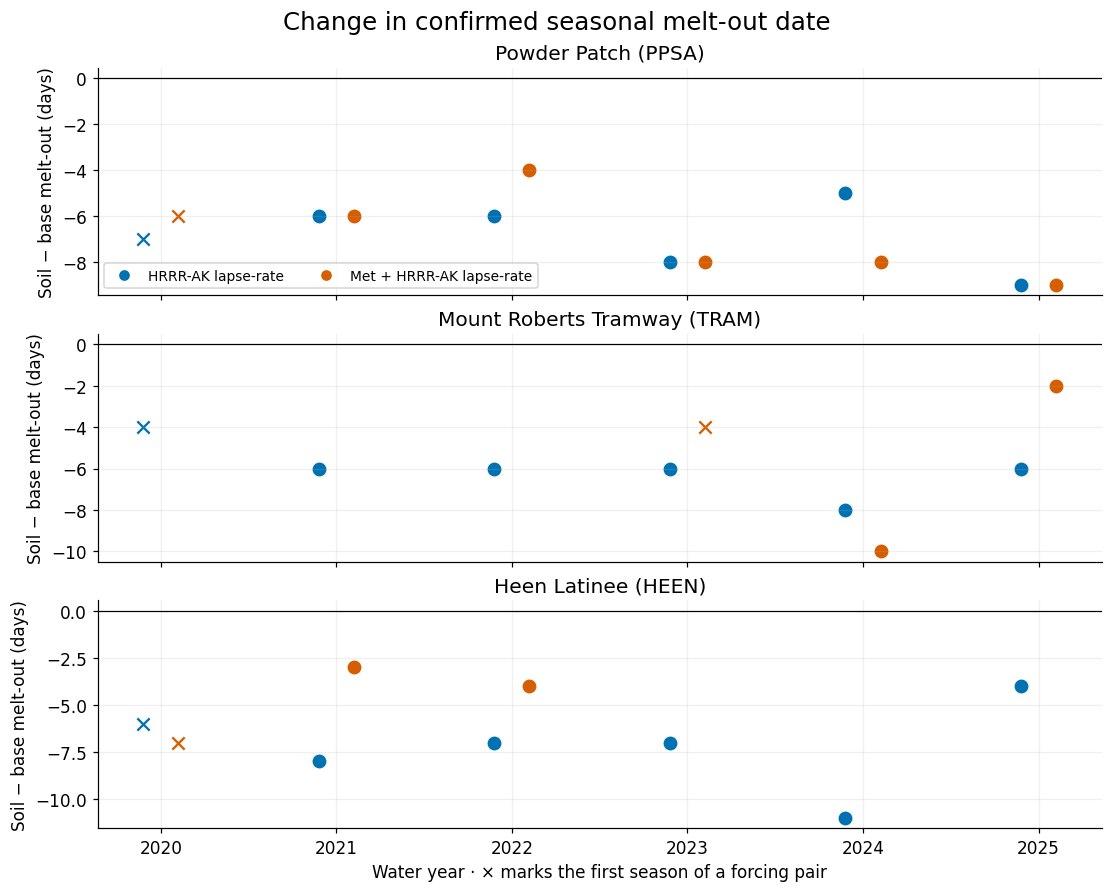

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout='constrained')
for (site, config), ax in zip(SITE_CONFIG.items(), axes):
    for offset, forcing in zip([-.10, .10], FORCINGS):
        rows = metrics[(metrics.site == site) & (metrics.forcing == forcing)]
        for _, row in rows.iterrows():
            if pd.isna(row.melt_shift_days):
                continue
            ax.scatter(row.water_year + offset, row.melt_shift_days,
                       color=COLORS[forcing], s=65,
                       marker='x' if row.initialization_sensitive else 'o')
        ax.plot([], [], color=COLORS[forcing], marker='o', ls='', label=LABELS[forcing])
    ax.axhline(0, color='black', lw=.8)
    ax.set(title=config['title'], ylabel='Soil − base melt-out (days)')
    ax.grid(alpha=.2)
axes[0].legend(ncol=2, fontsize=9)
axes[-1].set(xlabel='Water year · × marks the first season of a forcing pair', xticks=range(2020, 2026))
fig.suptitle('Change in confirmed seasonal melt-out date', fontsize=16)

plt.show()


## Spring development in the main comparison years

Each panel shows February–August of one water year. The same four simulations and observations are shown. This zoom complements the full snow-depth and difference figures; no smoothing is applied to model data.

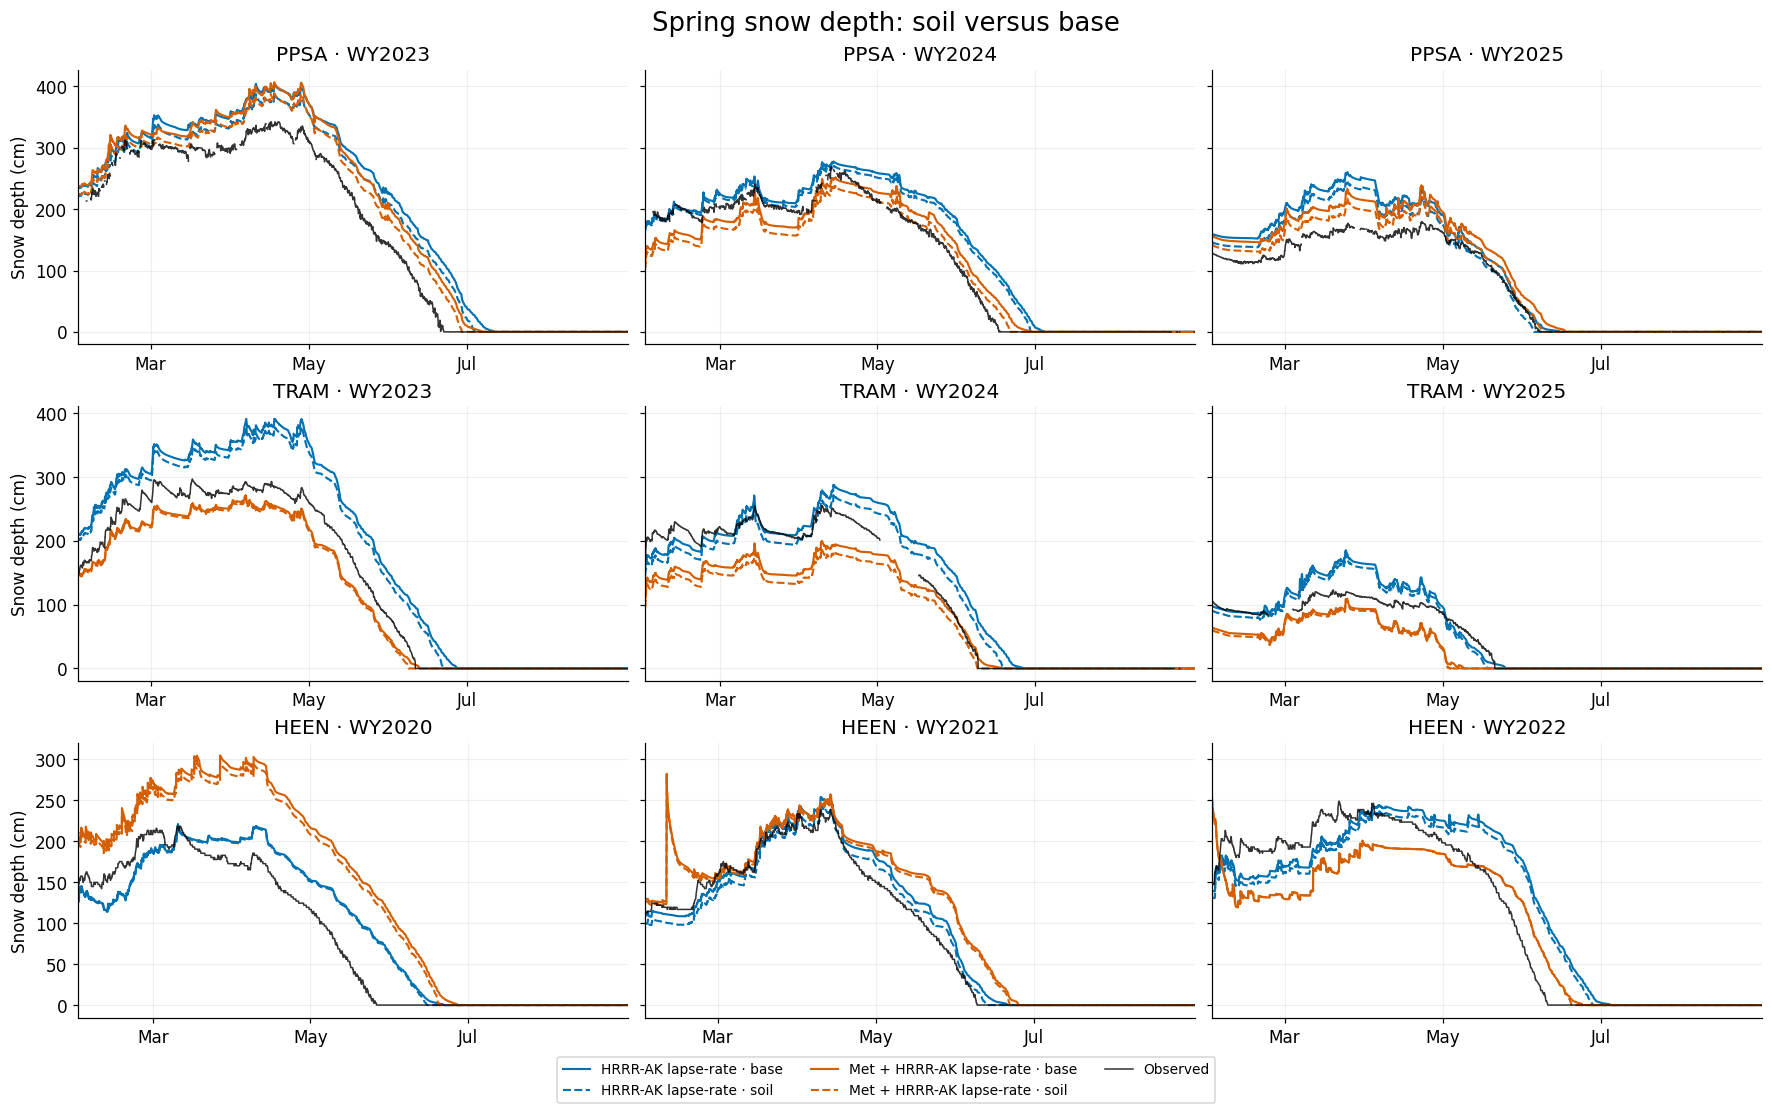

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharey='row', layout='constrained')
for row, (site, config) in enumerate(SITE_CONFIG.items()):
    years = [2020, 2021, 2022] if site == 'heen' else [2023, 2024, 2025]
    for column, year in enumerate(years):
        ax = axes[row, column]
        start, end = pd.Timestamp(year, 2, 1), pd.Timestamp(year, 8, 31, 23)
        for forcing in FORCINGS:
            for experiment in ('base', 'soil'):
                curve = models[(site, forcing, experiment)].loc[start:end, 'HS_cm']
                ax.plot(curve.index, curve, color=COLORS[forcing], ls=STYLES[experiment], lw=1.4,
                        label=f'{LABELS[forcing]} · {experiment}')
        obs = observations[site].loc[start:end]
        ax.plot(obs.index, obs, color='black', lw=1.0, alpha=.8, label='Observed')
        ax.set(title=f'{site.upper()} · WY{year}', xlim=(start, end))
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
        ax.grid(alpha=.2)
        if column == 0:
            ax.set_ylabel('Snow depth (cm)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=9)
fig.suptitle('Spring snow depth: soil versus base', fontsize=17)

plt.show()


## Interpret the soil sensitivity

The summary separates all seasons from seasons after initialization. A change can be physically meaningful without improving observation agreement. Judge the size of the soil/base difference against model–observation errors, year-to-year consistency, melt timing, and the assumed soil properties; this single idealized soil experiment cannot establish that the chosen soil profile is accurate or universally necessary. In particular, the base runs impose constant TSG, while soil runs calculate ground temperature and fluxes, so the contrast includes that changed lower-boundary treatment.

In [9]:
summary_rows = []
for (site, forcing), rows in metrics.groupby(['site', 'forcing'], sort=False):
    for period, use in [('all seasons', rows), ('after first season', rows[~rows.initialization_sensitive])]:
        if use.empty:
            continue
        melt = use.melt_shift_days.dropna()
        error = use.dropna(subset=['RMSE_change_cm'])
        summary_rows.append(dict(site=site, forcing=forcing, period=period, seasons=len(use),
            median_mean_abs_depth_change_cm=use.mean_absolute_delta_HS_cm.median(),
            median_peak_depth_change_cm=use.peak_HS_change_cm.median(),
            confirmed_melt_pairs=len(melt),
            median_melt_shift_days=melt.median() if len(melt) else np.nan,
            min_melt_shift_days=melt.min() if len(melt) else np.nan,
            max_melt_shift_days=melt.max() if len(melt) else np.nan,
            seasons_with_lower_RMSE=int((error.RMSE_change_cm < 0).sum()),
            seasons_with_obs=len(error), median_RMSE_change_cm=error.RMSE_change_cm.median()))
summary = pd.DataFrame(summary_rows)
summary.to_csv(FIGURE_DIR / 'soil_sensitivity_summary.csv', index=False)
display(summary.round(2))
print('Positive melt shift = later soil melt-out; negative = earlier.')
print('Negative RMSE change = improved agreement with observations.')
print('Missing melt dates remain missing; inspect status columns in soil_seasonal_metrics.csv.')
print(f'Diagnostic CSV tables saved to {FIGURE_DIR}; figures displayed inline')

for site, rows in metrics.groupby('site', sort=False):
    valid_melt = rows.melt_shift_days.dropna()
    valid_error = rows.dropna(subset=['RMSE_change_cm'])
    print(f"{site.upper()}: soil melt-out shift {valid_melt.min():.0f} to {valid_melt.max():.0f} days; "
          f"snow-depth RMSE lower in {(valid_error.RMSE_change_cm < 0).sum()}/{len(valid_error)} forcing-seasons.")
print('The soil treatment changes melt timing in these experiments, but observation agreement does not improve uniformly.')


,site,forcing,period,seasons,median_mean_abs_depth_change_cm,median_peak_depth_change_cm,confirmed_melt_pairs,median_melt_shift_days,min_melt_shift_days,max_melt_shift_days,seasons_with_lower_RMSE,seasons_with_obs,median_RMSE_change_cm
0,ppsa,hrrr,all seasons,6,8.71,-14.56,6,-6.5,-9,-5,5,6,-4.69
1,ppsa,hrrr,after first season,5,9.13,-14.37,5,-6.0,-9,-5,4,5,-3.99
2,ppsa,mixed,all seasons,6,7.99,-14.07,6,-7.0,-9,-4,3,6,-1.53
3,ppsa,mixed,after first season,5,7.23,-13.87,5,-8.0,-9,-4,2,5,0.13
4,tram,hrrr,all seasons,6,5.15,-9.61,6,-6.0,-8,-4,6,6,-5.04
5,tram,hrrr,after first season,5,5.90,-12.43,5,-6.0,-8,-6,5,5,-5.10
6,tram,mixed,all seasons,3,2.21,-3.28,3,-4.0,-10,-2,0,3,2.33
7,tram,mixed,after first season,2,4.40,-6.70,2,-6.0,-10,-2,0,2,4.75
8,heen,hrrr,all seasons,6,5.28,-8.18,6,-7.0,-11,-4,4,6,-0.93
9,heen,hrrr,after first season,5,5.32,-8.55,5,-7.0,-11,-4,3,5,-1.27


Positive melt shift = later soil melt-out; negative = earlier.
Negative RMSE change = improved agreement with observations.
Missing melt dates remain missing; inspect status columns in soil_seasonal_metrics.csv.
Figures and CSV tables saved to /home/cassie/python/repos/snow_modeling_point/figures/soil_comparison
PPSA: soil melt-out shift -9 to -4 days; snow-depth RMSE lower in 8/12 forcing-seasons.
TRAM: soil melt-out shift -10 to -2 days; snow-depth RMSE lower in 6/9 forcing-seasons.
HEEN: soil melt-out shift -11 to -3 days; snow-depth RMSE lower in 7/9 forcing-seasons.
The soil treatment changes melt timing in these experiments, but observation agreement does not improve uniformly.
